In [16]:
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
# 1-2 Import and Explore

df=pd.read_csv("City_Air_Quality.csv")
df.head()

,Date,AQI,PM2.5,PM10,CO
0,2024-01-01,164.0,93.9,181.5,0.79
1,2024-01-02,125.0,67.2,145.3,1.56
2,2024-01-03,185.0,105.3,217.8,1.14
3,2024-01-04,185.0,110.6,208.7,0.94
4,2024-01-05,86.0,53.7,98.1,1.24


In [18]:
df.shape

(366, 5)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    366 non-null    object 
 1   AQI     361 non-null    float64
 2   PM2.5   366 non-null    float64
 3   PM10    366 non-null    float64
 4   CO      366 non-null    float64
dtypes: float64(4), object(1)
memory usage: 14.4+ KB


In [20]:
df.describe()

,AQI,PM2.5,PM10,CO
count,361.000000,366.000000,366.000000,366.000000
mean,99.664820,56.662295,107.476776,0.844235
std,49.069804,27.927582,53.693865,0.462028
min,20.000000,13.300000,27.000000,0.200000
25%,57.000000,30.950000,60.475000,0.472500
50%,96.000000,53.700000,100.400000,0.770000
75%,138.000000,77.125000,146.400000,1.140000
max,253.000000,148.200000,296.300000,2.920000


In [21]:
# 3. Relevant Variables
df["Date"]=pd.to_datetime(df["Date"])
df=df.sort_values("Date").dropna(subset=["AQI"])

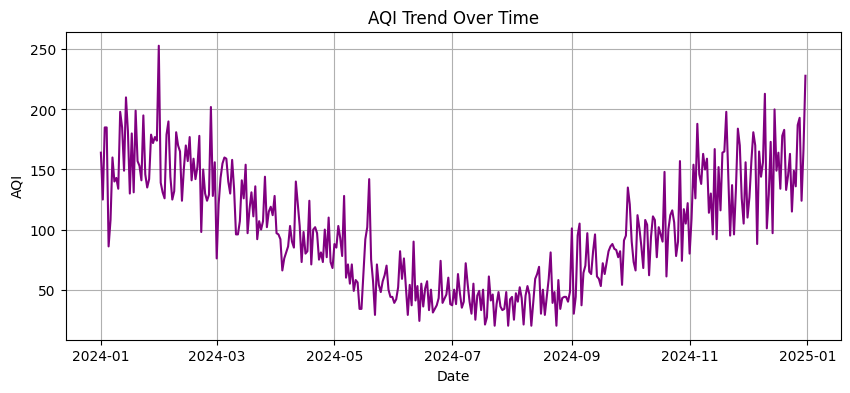

In [22]:
# 4. Overall AQI Trends
plt.figure(figsize=(10, 4))
plt.plot(df["Date"], df["AQI"], color="purple")
plt.title("AQI Trend Over Time"); plt.xlabel("Date"); plt.ylabel("AQI")
plt.grid(True); plt.show()

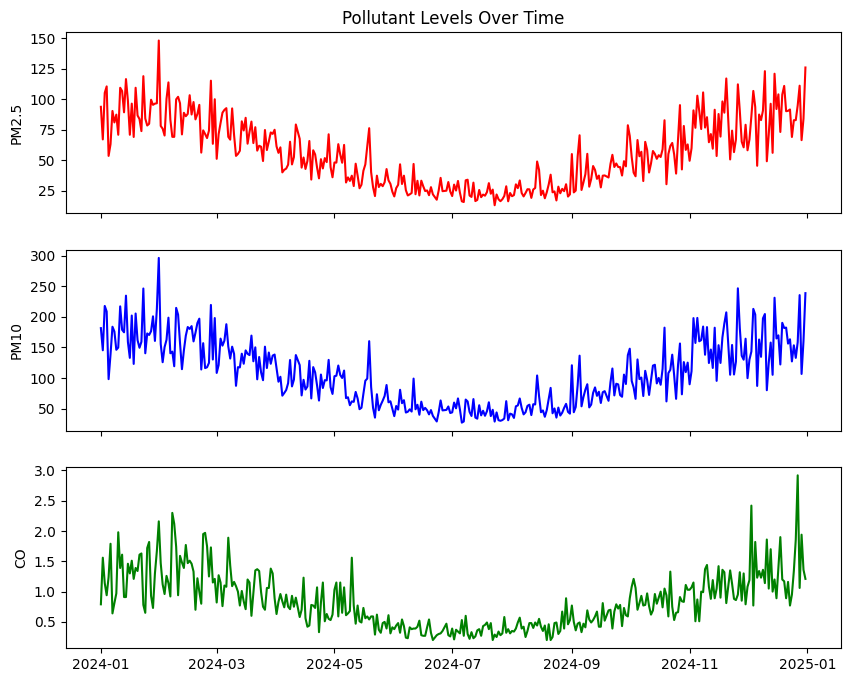

In [23]:
# 5. Individual pollutant trends
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, col, color in zip(axes, ["PM2.5", "PM10", "CO"], ["red", "blue", "green"]):
 ax.plot(df["Date"], df[col], color=color)
 ax.set_ylabel(col)
axes[0].set_title("Pollutant Levels Over Time")
plt.show()

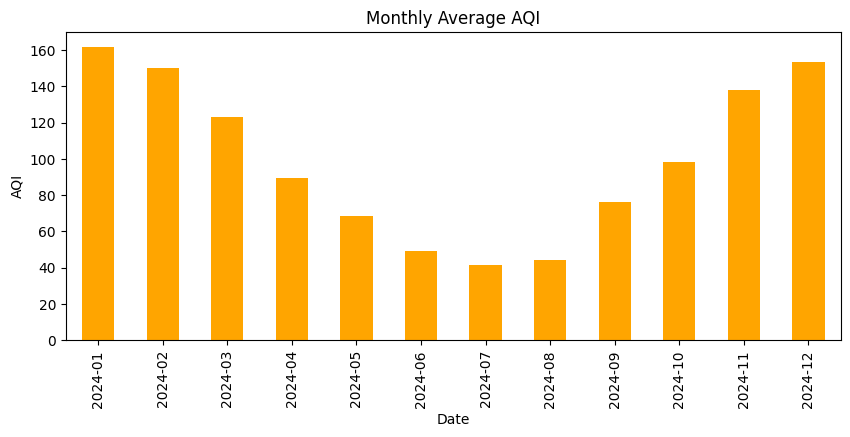

In [25]:
# 6. Bar plot (monthly average AQI)
monthly = df.groupby(df["Date"].dt.to_period("M"))["AQI"].mean()
monthly.plot(kind="bar", figsize=(10, 4), color="orange", title="Monthly Average AQI")
plt.ylabel("AQI"); plt.show()

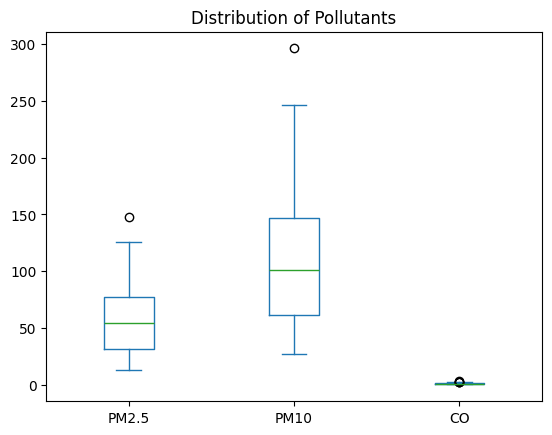

In [ ]:
# 7. Box plot of pollutant distributions
df[["PM2.5", "PM10", "CO"]].plot(kind="box", title="Distribution of Pollutants")
plt.show()

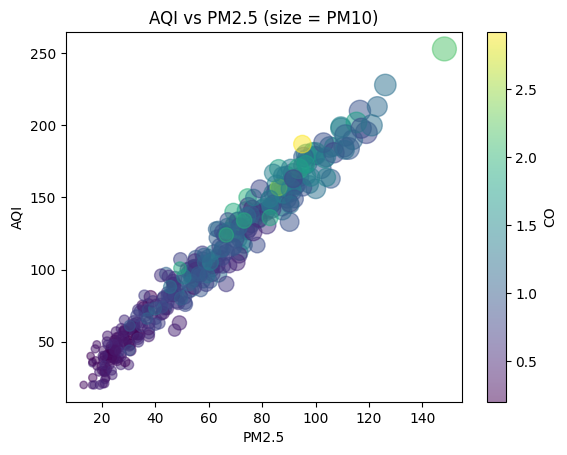

In [28]:
# 8. Scatter / bubble plot (AQI vs PM2.5)
plt.scatter(df["PM2.5"], df["AQI"], s=df["PM10"], alpha=0.5, c=df["CO"], cmap="viridis")
plt.colorbar(label="CO")
plt.xlabel("PM2.5"); plt.ylabel("AQI"); plt.title("AQI vs PM2.5 (size = PM10)")
plt.show()